# Практическая работа №2 - графы

## Команда №1

Горюхин Ковальский Нахаев Орлов

## Входные данные

В качестве альтернативы исходному заданию взят публичный датасет "Zachary's Karate Club". Задача - определить в графе связей центры по трём подходам: посредничество, близость и собственный вектор.

Для работы с графами используется библиотека networkx.

In [43]:
%pip install networkx matplotlib pandas

Note: you may need to restart the kernel to use updated packages.


In [2]:
import matplotlib.pyplot as plt
import pandas as pd
import networkx as nx


In [3]:
# pretty graphs
%matplotlib inline
plt.rcParams['figure.figsize'] = (8, 6)


In [4]:
G = nx.karate_club_graph()

print(f"Узлов (членов клуба): {G.number_of_nodes()}")
print(f"Рёбер (дружеских связей): {G.number_of_edges()}")
print(f"Средняя степень: {sum(dict(G.degree()).values()) / G.number_of_nodes():.2f}")
print(f"Диаметр графа: {nx.diameter(G)}")
print(f"Коэффициент кластеризации: {nx.average_clustering(G):.4f}")


Узлов (членов клуба): 34
Рёбер (дружеских связей): 78
Средняя степень: 4.59
Диаметр графа: 5
Коэффициент кластеризации: 0.5706


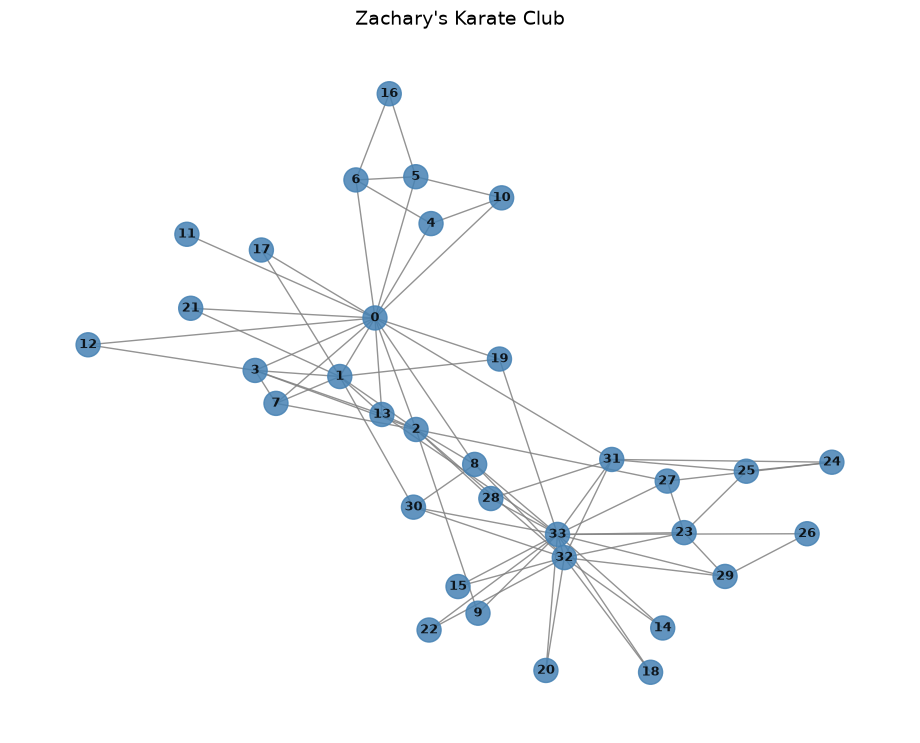

In [12]:
pos = nx.spring_layout(G, seed=42)  # фиксированный seed для воспроизводимости

# Узлы 0 (инструктор Mr. Hi) и 33 (президент John A.) — ключевые фигуры
node_colors = ['steelblue' for n in G.nodes()]
node_sizes  = [300 for n in G.nodes()]

plt.figure(figsize=(9, 7))
nx.draw(
    G, pos,
    node_color=node_colors,
    node_size=node_sizes,
    with_labels=True,
    font_size=9,
    font_weight='bold',
    edge_color='gray',
    alpha=0.85
)
plt.title("Zachary's Karate Club", fontsize=14)
plt.show()


## Центральность графа
Центральность вершин в графе – это вектор, сопоставляющей каждой
вершине графа некоторое число (индекс).

Центральность по близости оценивает, насколько близко вершина N находится ко всем остальным.

Центральность по посредничеству оценивает, как много кратчайших путей из каждой вершины в каждую другую проходит через вершину N.

Центральность по собственному вектору оценивает центральность вершины через центральности соседних вершин

### Реализация средствами networkx

In [19]:
# 1. Betweenness (посредничество)
nx_betweenness = nx.betweenness_centrality(G)

# 2. Closeness (близость)
nx_closeness = nx.closeness_centrality(G)

# 3. Eigenvector (собственный вектор)
nx_eigenvector = nx.eigenvector_centrality(G, max_iter=1000)

df_nx = pd.DataFrame({
    'nx Betweenness': nx_betweenness,
    'nx Closeness':   nx_closeness,
    'nx Eigenvector': nx_eigenvector
})

df_nx = df_nx.sort_values('nx Eigenvector', ascending=False)
df_nx.index.name = 'Узел'


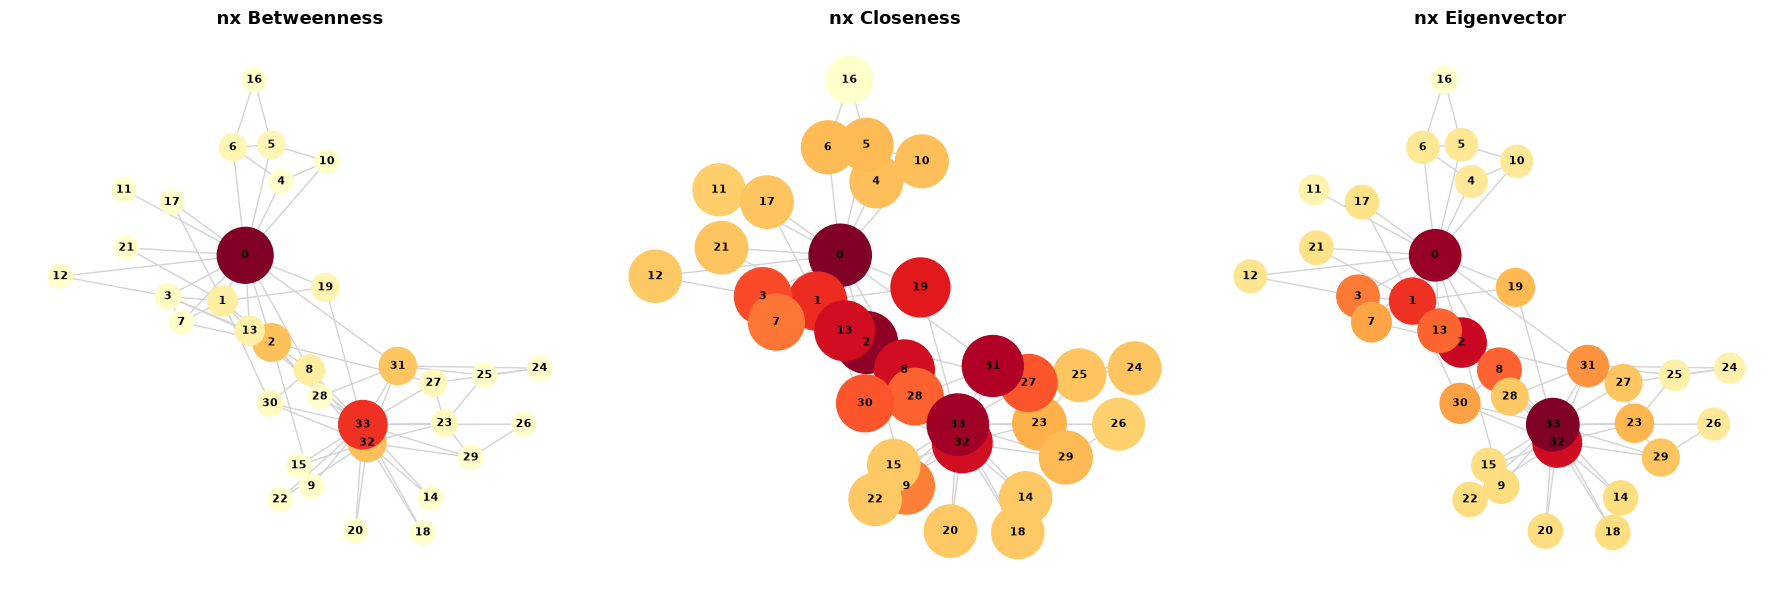

In [20]:
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
metrics = {
    'nx Betweenness': nx_betweenness,
    'nx Closeness':   nx_closeness,
    'nx Eigenvector': nx_eigenvector
}

for ax, (name, values) in zip(axes, metrics.items()):
    sizes  = [300 + 3000 * values[n] for n in G.nodes()]
    colors = [values[n] for n in G.nodes()]

    nx.draw(
        G, pos, ax=ax,
        node_size=sizes,
        node_color=colors,
        cmap=plt.cm.YlOrRd,
        with_labels=True,
        font_size=8,
        font_weight='bold',
        edge_color='lightgray'
    )
    ax.set_title(name, fontsize=13, fontweight='bold')

plt.tight_layout()
plt.show()


In [34]:
print("=" * 50)
for metric in ['nx Betweenness', 'nx Closeness', 'nx Eigenvector']:
    top = df_nx[metric].idxmax()
    print(f"Лидер по {metric:>12}: узел {top:>2}  ({df.loc[top, metric]:.4f})")
print("=" * 50)


Лидер по nx Betweenness: узел  0  (0.4376)
Лидер по nx Closeness: узел  0  (0.5690)
Лидер по nx Eigenvector: узел 33  (0.3734)


### Ручная реализация

In [30]:
from collections import deque
import numpy as np


In [28]:
def get_betweenness(G):
    nodes = list(G.nodes())
    n = len(nodes)
    CB = {v: 0.0 for v in nodes}

    for s in nodes:
        # --- BFS ---
        S = []
        P = {v: [] for v in nodes}
        sigma = {v: 0 for v in nodes}
        sigma[s] = 1
        d = {v: -1 for v in nodes}
        d[s] = 0
        Q = deque([s])

        while Q:
            v = Q.popleft()
            S.append(v)
            for w in G.neighbors(v):
                if d[w] < 0:
                    d[w] = d[v] + 1
                    Q.append(w)
                if d[w] == d[v] + 1:
                    sigma[w] += sigma[v]
                    P[w].append(v)

        # --- reverse ---
        delta = {v: 0.0 for v in nodes}
        while S:
            w = S.pop()
            for v in P[w]:
                delta[v] += (sigma[v] / sigma[w]) * (1 + delta[w])
            if w != s:
                CB[w] += delta[w]

    norm = (n - 1) * (n - 2)
    for v in nodes:
        CB[v] /= (2.0 * norm) if norm else 1.0

    return CB


def get_closeness(G):
    nodes = list(G.nodes())
    n = len(nodes)
    CC = {}

    for s in nodes:
        # BFS from S
        d = {v: -1 for v in nodes}
        d[s] = 0
        Q = deque([s])

        while Q:
            v = Q.popleft()
            for w in G.neighbors(v):
                if d[w] < 0:
                    d[w] = d[v] + 1
                    Q.append(w)

        total_dist = sum(d[v] for v in nodes if d[v] > 0)
        CC[s] = (n - 1) / total_dist if total_dist > 0 else 0.0

    return CC


def get_eigenvector(G, max_iter=1000, tol=1e-6):
    nodes = list(G.nodes())
    n = len(nodes)
    idx = {v: i for i, v in enumerate(nodes)}

    # neighbor matrix
    A = np.zeros((n, n))
    for u, v in G.edges():
        A[idx[u], idx[v]] = 1
        A[idx[v], idx[u]] = 1

    x = np.ones(n) / n

    for _ in range(max_iter):
        x_new = A @ x
        norm = np.linalg.norm(x_new)
        if norm == 0:
            break
        x_new /= norm

        if np.linalg.norm(x_new - x) < tol:
            x = x_new
            break
        x = x_new

    return {nodes[i]: float(x[i]) for i in range(n)}
    

In [42]:
# 1. Betweenness (посредничество)
man_betweenness = get_betweenness(G)

# 2. Closeness (близость)
man_closeness = get_closeness(G)

# 3. Eigenvector (собственный вектор)
man_eigenvector = get_eigenvector(G, max_iter=1000)

df_man = pd.DataFrame({
    'manual Betweenness': man_betweenness,
    'manual Closeness':   man_closeness,
    'manual Eigenvector': man_eigenvector
})

df_man = df_man.sort_values('manual Eigenvector', ascending=False)
df_man.index.name = 'Узел'


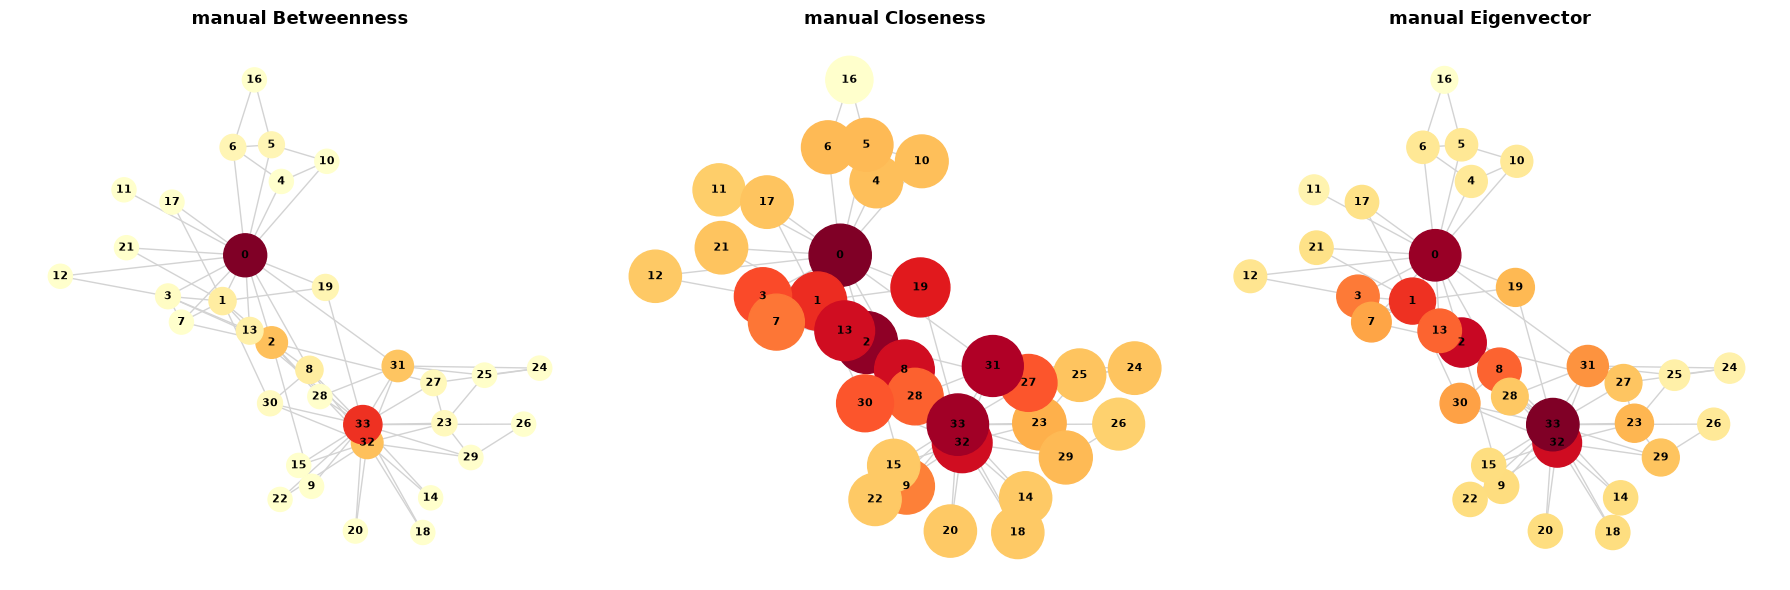

In [37]:
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
metrics = {
    'manual Betweenness': man_betweenness,
    'manual Closeness':   man_closeness,
    'manual Eigenvector': man_eigenvector
}

for ax, (name, values) in zip(axes, metrics.items()):
    sizes  = [300 + 3000 * values[n] for n in G.nodes()]
    colors = [values[n] for n in G.nodes()]

    nx.draw(
        G, pos, ax=ax,
        node_size=sizes,
        node_color=colors,
        cmap=plt.cm.YlOrRd,
        with_labels=True,
        font_size=8,
        font_weight='bold',
        edge_color='lightgray'
    )
    ax.set_title(name, fontsize=13, fontweight='bold')

plt.tight_layout()
plt.show()


In [41]:
print("=" * 50)
for metric in ['manual Betweenness', 'manual Closeness', 'manual Eigenvector']:
    top = df_man[metric].idxmax()
    print(f"Лидер по {metric:>12}: узел {top:>2}  ({df_man.loc[top, metric]:.4f})")
print("=" * 50)


Лидер по manual Betweenness: узел  0  (0.2188)
Лидер по manual Closeness: узел  0  (0.5690)
Лидер по manual Eigenvector: узел 33  (0.3734)
